# Library

In [1]:
!pip install tf2onnx onnxruntime

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import json
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)
import matplotlib.pyplot as plt


# preprocessing
from sklearn.impute import SimpleImputer
from sklearn import preprocessing
from collections import Counter
from sklearn.pipeline import Pipeline
from sklearn import clone
# CV dan evaluasi
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, precision_score, recall_score

# Model A (pilih salah satu)
from xgboost import XGBClassifier
# from lightgbm import LGBMClassifier

# Model B
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, Dropout, BatchNormalization

# export ANN ke ONNX
import tf2onnx
import onnxruntime as ort

# Data Pre-Processing

In [3]:
df = pd.read_csv('/content/sepsis_emr_data.csv')
df.head()

,patient_id,heart_rate,respiratory_rate,temperature,wbc_count,lactate_level,age,num_comorbidities,sepsis_risk
0,PID0001,88,17,37.1,7.9,1.1,51,1,0
1,PID0002,115,25,38.6,16.0,3.6,78,3,1
2,PID0003,79,16,36.9,7.1,0.9,42,0,0
3,PID0004,96,20,37.5,10.2,1.6,65,2,0
4,PID0005,122,29,39.2,18.1,4.7,83,4,1


In [4]:
df.shape

(1753, 9)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1753 entries, 0 to 1752
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   patient_id         1753 non-null   object 
 1   heart_rate         1753 non-null   int64  
 2   respiratory_rate   1753 non-null   int64  
 3   temperature        1753 non-null   float64
 4   wbc_count          1753 non-null   float64
 5   lactate_level      1612 non-null   float64
 6   age                1753 non-null   int64  
 7   num_comorbidities  1753 non-null   int64  
 8   sepsis_risk        1753 non-null   int64  
dtypes: float64(3), int64(5), object(1)
memory usage: 123.4+ KB


In [6]:
df.isna().sum()

,0
patient_id,0
heart_rate,0
respiratory_rate,0
temperature,0
wbc_count,0
lactate_level,141
age,0
num_comorbidities,0
sepsis_risk,0


In [7]:
df.groupby(df['lactate_level'].isna())['sepsis_risk'].mean()

,sepsis_risk
lactate_level,
False,0.456576
True,0.000000


In [8]:
from scipy.stats import chi2_contingency

tabel = pd.crosstab(df['lactate_level'].isna(), df['sepsis_risk'])
chi2, p, dof, expected = chi2_contingency(tabel)
print(tabel)
print(p)

sepsis_risk      0    1
lactate_level          
False          876  736
True           141    0
1.5428637217042255e-25


In [9]:
df.describe()

,heart_rate,respiratory_rate,temperature,wbc_count,lactate_level,age,num_comorbidities,sepsis_risk
count,1753.000000,1753.000000,1753.000000,1753.000000,1612.000000,1753.000000,1753.000000,1753.000000
mean,102.389618,21.380491,37.677981,12.153337,2.498325,62.423274,1.938962,0.419852
std,18.910763,5.042129,0.897800,4.239124,1.397458,16.896812,1.264295,0.493675
min,76.000000,14.000000,35.700000,6.100000,0.800000,29.000000,0.000000,0.000000
25%,88.000000,17.000000,36.900000,8.000000,1.200000,48.000000,1.000000,0.000000
50%,99.000000,20.000000,37.500000,11.200000,2.100000,65.000000,2.000000,0.000000
75%,115.000000,26.000000,38.500000,16.100000,3.700000,76.000000,3.000000,1.000000
max,220.000000,31.000000,39.400000,19.600000,5.300000,91.000000,4.000000,1.000000


In [10]:
df['sepsis_risk'].value_counts()

,count
sepsis_risk,
0,1017
1,736


In [11]:
df.duplicated(subset=df.columns.drop(['patient_id', 'sepsis_risk'])).sum()

np.int64(1653)

In [12]:
df = df.drop_duplicates(subset=df.columns.drop(['patient_id', 'sepsis_risk']))

In [13]:
df.shape

(100, 9)

In [14]:
#pisahkan fitur dan target
X = df.drop(['patient_id', 'sepsis_risk'], axis=1).values
y = df['sepsis_risk'].values

In [15]:
Counter(y)

Counter({np.int64(0): 58, np.int64(1): 42})

In [16]:
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', preprocessing.StandardScaler())
])

In [17]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for fold, (train_index, test_index) in enumerate(skf.split(X, y), 1):
    X_train, X_test = X[train_index], X[test_index]

    prep = clone(preprocessor)
    X_train_prep = prep.fit_transform(X_train)
    X_test_prep = prep.transform(X_test)
    print(f"Fold {fold}: train {X_train_prep.shape}, test {X_test_prep.shape}")

Fold 1: train (80, 7), test (20, 7)
Fold 2: train (80, 7), test (20, 7)
Fold 3: train (80, 7), test (20, 7)
Fold 4: train (80, 7), test (20, 7)
Fold 5: train (80, 7), test (20, 7)


# Pembuatan Model

## Machine Learning Klasik

In [18]:
#modelling
model_a = XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    random_state=42
)

proba_a = np.zeros(len(y))

for fold, (train_index, test_index) in enumerate(skf.split(X, y), 1):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    prep = clone(preprocessor)
    X_train_prep = prep.fit_transform(X_train)
    X_test_prep = prep.transform(X_test)

    model_a_fold = clone(model_a)
    model_a_fold.fit(X_train_prep, y_train)
    proba_a[test_index] = model_a_fold.predict_proba(X_test_prep)[:, 1]

    print(f"Fold {fold} selesai")

Fold 1 selesai
Fold 2 selesai
Fold 3 selesai
Fold 4 selesai
Fold 5 selesai


## Artificial Neural Network

In [19]:
model_b = Sequential([
    Dense(16, activation='relu', input_shape=(7,)),  # 16 neuron cukup buat data kecil, relu default hidden layer
    Dropout(0.5),                                    # cegah overfitting
    Dense(1, activation='sigmoid')                   # output probabilitas sepsis (binary)
])

model_b.compile(
    optimizer='Adam',              # optimizer yang umum dipakai, learning rate-nya nyesuaiin sendiri
    loss='binary_crossentropy',    # loss buat klasifikasi binary dengan output sigmoid
    metrics=['accuracy']           # cuma buat dipantau waktu training, metrik utama dihitung di Evaluation
)
tf.keras.utils.set_random_seed(42)  # biar hasil ANN bisa diulang
proba_b = np.zeros(len(y))

for fold, (train_index, test_index) in enumerate(skf.split(X, y), 1):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    prep = clone(preprocessor)
    X_train_prep = prep.fit_transform(X_train)
    X_test_prep = prep.transform(X_test)

    model_b_fold = tf.keras.models.clone_model(model_b)  # padanan clone buat Keras, bobotnya baru
    model_b_fold.compile(optimizer='Adam', loss='binary_crossentropy', metrics=['accuracy'])
    model_b_fold.fit(X_train_prep, y_train, epochs=100, verbose=0)
    proba_b[test_index] = model_b_fold.predict(X_test_prep, verbose=0).ravel()

    print(f"Fold {fold} selesai")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Fold 1 selesai
Fold 2 selesai
Fold 3 selesai
Fold 4 selesai


Fold 5 selesai


## Ensemble Learning xgboost + ann

In [20]:
# soft voting ensemble: rata-rata terbobot probabilitas dua model
w_a = 0.5
w_b = 0.5
proba_ens = w_a * proba_a + w_b * proba_b

# Evalution

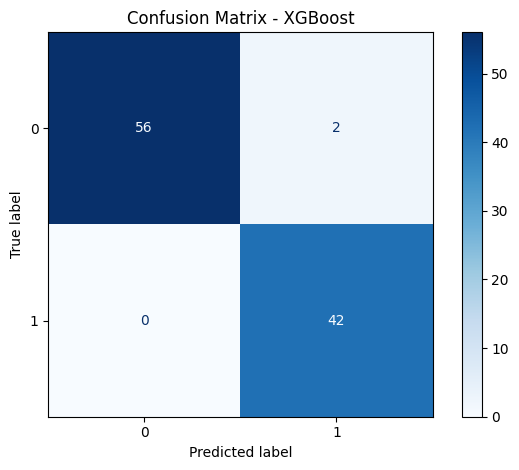

Precision: 0.9545454545454546
Recall   : 1.0
AUC-ROC  : 0.9753694581280788


In [21]:
# model klsik
y_prob_a = proba_a
y_pred_a = (proba_a >= 0.5).astype(int)

cm = confusion_matrix(y, y_pred_a)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - XGBoost")
plt.grid(False)
plt.tight_layout()
plt.show()

print("Precision:", precision_score(y, y_pred_a))
print("Recall   :", recall_score(y, y_pred_a))
print("AUC-ROC  :", roc_auc_score(y, y_prob_a))

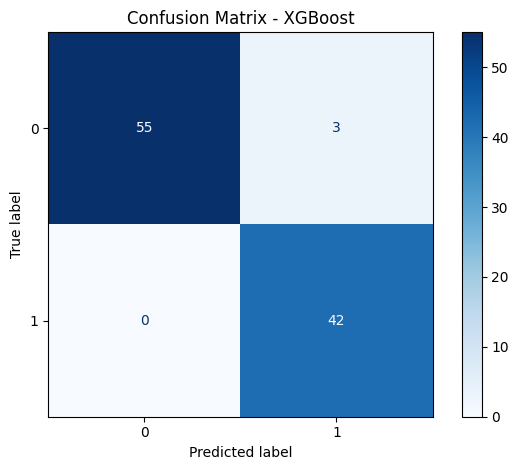

Precision: 0.9333333333333333
Recall   : 1.0
AUC-ROC  : 0.9827586206896551


In [22]:
# model ann
y_prob_b = proba_b
y_pred_b = (proba_b >= 0.5).astype(int)

cm = confusion_matrix(y, y_pred_b)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - ANN")
plt.grid(False)
plt.tight_layout()
plt.show()

print("Precision:", precision_score(y, y_pred_b))
print("Recall   :", recall_score(y, y_pred_b))
print("AUC-ROC  :", roc_auc_score(y, y_prob_b))

In [23]:
# alasan bobot 50/50: AUC dua model hampir sama
auc_a = roc_auc_score(y, proba_a)
auc_b = roc_auc_score(y, proba_b)
print("AUC XGBoost:", auc_a)
print("AUC ANN    :", auc_b)

AUC XGBoost: 0.9753694581280788
AUC ANN    : 0.9827586206896551


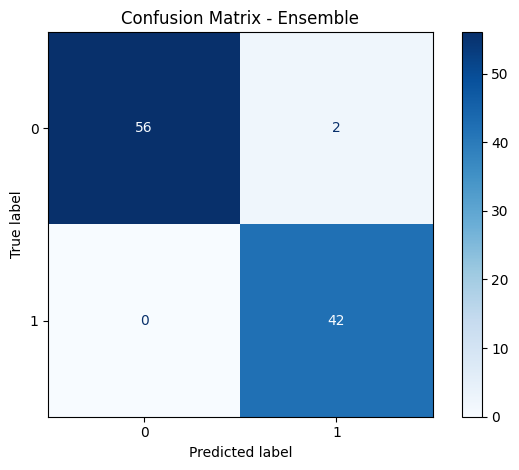

Precision: 0.9545454545454546
Recall   : 1.0
AUC-ROC  : 0.9827586206896551


In [24]:
# model ensemble
y_prob_ens = proba_ens
y_pred_ens = (proba_ens >= 0.5).astype(int)

cm = confusion_matrix(y, y_pred_ens)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - Ensemble")
plt.grid(False)
plt.tight_layout()
plt.show()

print("Precision:", precision_score(y, y_pred_ens))
print("Recall   :", recall_score(y, y_pred_ens))
print("AUC-ROC  :", roc_auc_score(y, y_prob_ens))

# Save Model

In [25]:
import os
os.makedirs('artifacts', exist_ok=True)

# 1. latih ulang pakai seluruh data
prep_final = clone(preprocessor)
X_prep = prep_final.fit_transform(X)

model_a_final = clone(model_a)
model_a_final.fit(X_prep, y)

model_b_final = tf.keras.models.clone_model(model_b)
model_b_final.compile(optimizer='Adam', loss='binary_crossentropy', metrics=['accuracy'])
model_b_final.fit(X_prep, y, epochs=100, verbose=0)

# 2. simpan preprocessor
joblib.dump(prep_final, 'artifacts/preprocessor.joblib')

# 3. simpan XGBoost (format JSON, aman lintas versi)
model_a_final.save_model('artifacts/model_a_xgb.json')

# 4. simpan ANN ke ONNX
spec = [tf.TensorSpec([None, 7], tf.float32, name='input')]
model_b_final.output_names = ['output']
tf2onnx.convert.from_keras(model_b_final, input_signature=spec, opset=13,
                           output_path='artifacts/model_b_ann.onnx')

# 5. simpan bobot ensemble dan threshold
config = {
    'features': list(df.columns.drop(['patient_id', 'sepsis_risk'])),
    'w_a': w_a,
    'w_b': w_b,
    'threshold': 0.5
}
with open('artifacts/ensemble_config.json', 'w') as f:
    json.dump(config, f, indent=2)

In [26]:
# load ulang artefak, bandingin sama model di memori
prep_l = joblib.load('artifacts/preprocessor.joblib')
model_a_l = XGBClassifier()
model_a_l.load_model('artifacts/model_a_xgb.json')
sess_b = ort.InferenceSession('artifacts/model_b_ann.onnx')

X_cek = prep_l.transform(X[:5])
pa = model_a_l.predict_proba(X_cek)[:, 1]
pb = sess_b.run(None, {sess_b.get_inputs()[0].name: X_cek.astype(np.float32)})[0].ravel()

print(type(prep_l))  # harus sklearn.pipeline.Pipeline
print(np.allclose(pa, model_a_final.predict_proba(X_prep[:5])[:, 1]))
print(np.allclose(pb, model_b_final.predict(X_prep[:5], verbose=0).ravel(), atol=1e-5))

<class 'sklearn.pipeline.Pipeline'>
True


True


In [27]:
!zip -r artifacts.zip artifacts

from google.colab import files
files.download('artifacts.zip')

updating: artifacts/ (stored 0%)
updating: artifacts/model_a_xgb.json (deflated 94%)
updating: artifacts/ensemble_config.json (deflated 39%)
updating: artifacts/preprocessor.joblib (deflated 33%)
updating: artifacts/model_b_ann.onnx (deflated 42%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
import sklearn, xgboost, onnxruntime, numpy, sys
print(sys.version)
print("numpy", numpy.__version__)
print("scikit-learn", sklearn.__version__)
print("xgboost", xgboost.__version__)
print("onnxruntime", onnxruntime.__version__)

3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
numpy 2.1.3
scikit-learn 1.6.1
xgboost 3.4.1
onnxruntime 1.31.0
